In [1]:
%load_ext autoreload
%autoreload 2

# Load hardware data

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"
# device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_62247/664675149.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

2 possible layouts


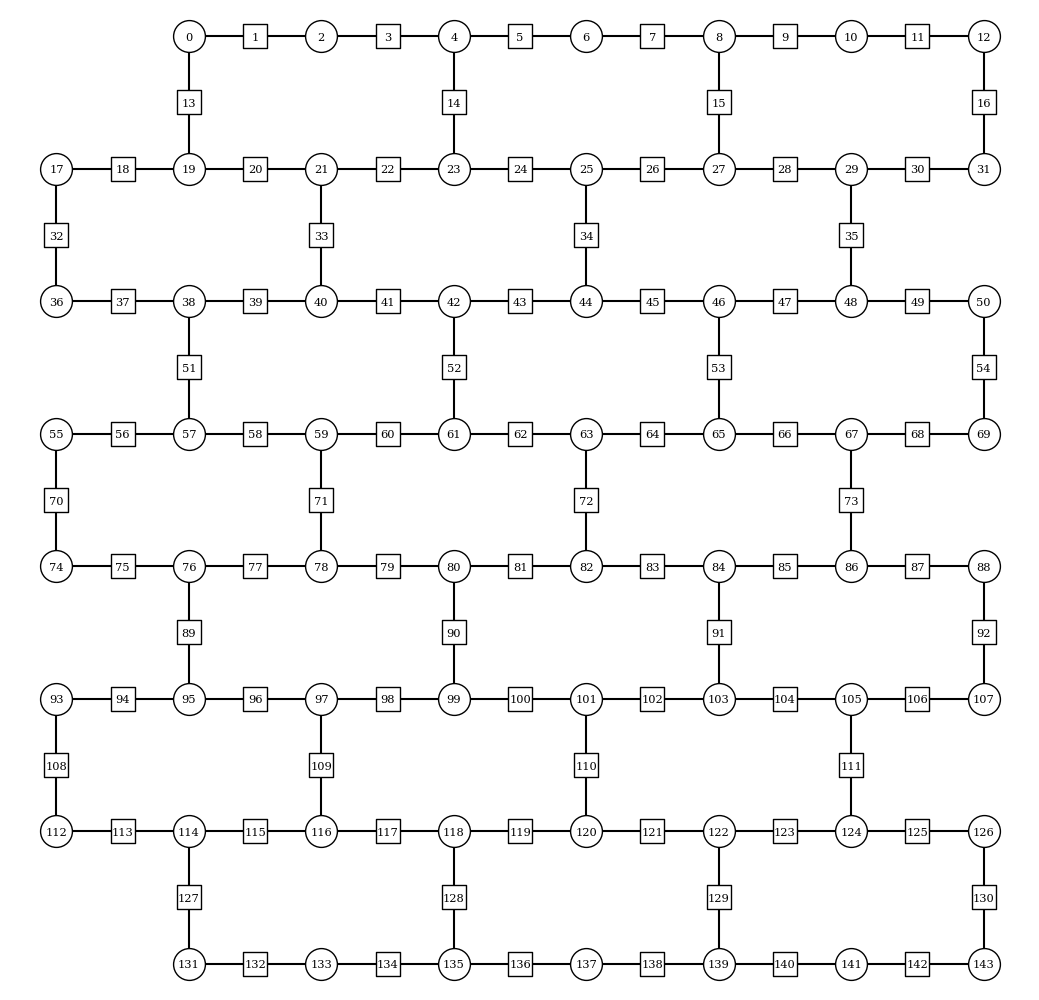

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 7

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

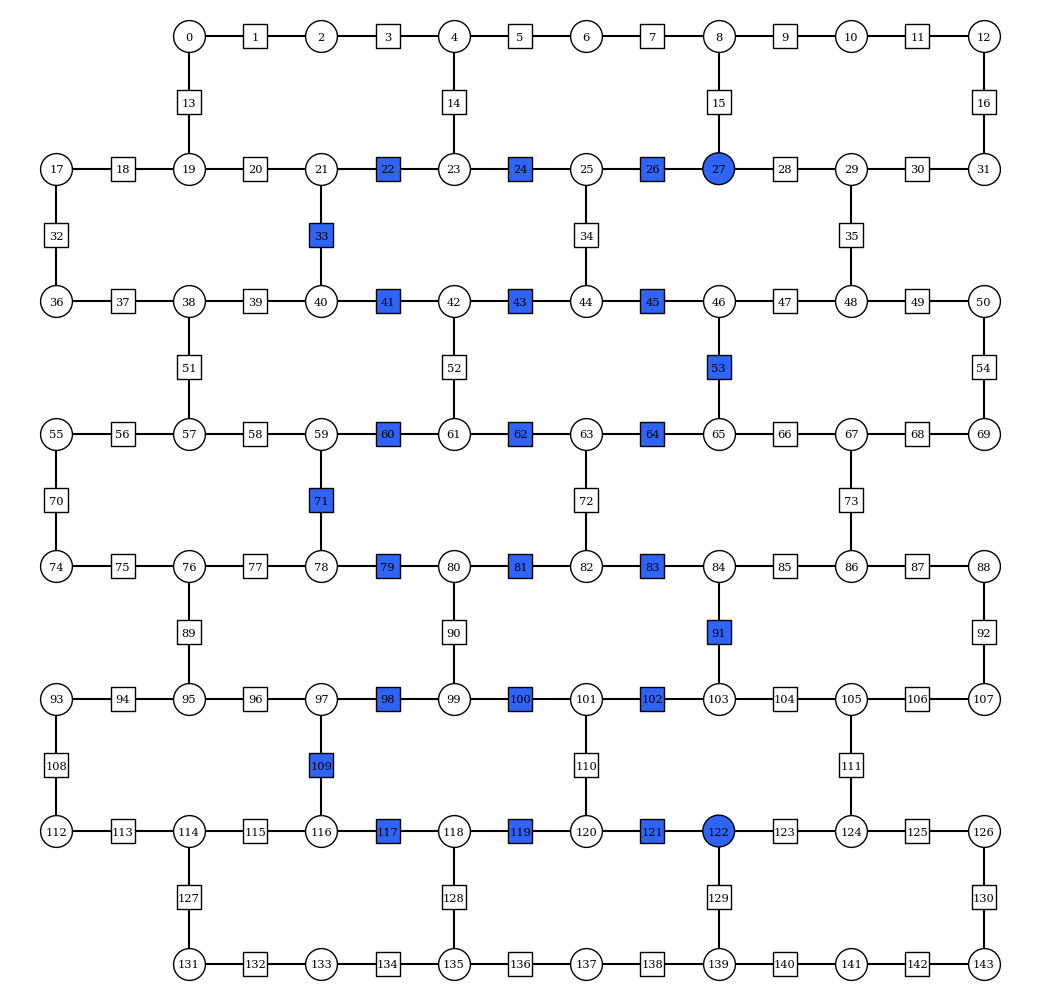

In [4]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 0
h = 0
lamb = 1

x_basis = False

fractional_gates = False

string = [27, 26, 24, 22, 33, 41, 43, 45, 53, 64, 62, 60, 71, 79, 81, 83, 91, 102, 100, 98, 109, 117, 119, 121, 122] # Benchmark

final_time = 7.5
dt = 0.25
steps = 60
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 300000
confidence = 0.9

odr = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 4
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
# g_func = zero_mean

sampler_options_args = [(False, False), (False, True)] # (DD, PT)
g_funcs = [None, zero_mean]

sampler_options = [{
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": a[0],
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": a[1],
        "enable_measure": a[1],
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
} for a in sampler_options_args]

execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True)

## Load jobs

In [5]:
from itertools import product
import pickle
import os

hardware_datas = [] # [(hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts)]

to_iterate = [(None, sampler_options[0]), (zero_mean, sampler_options[0]), (zero_mean, sampler_options[1])]
filepaths = []

for g_func, sampler_dict in to_iterate: #product(g_funcs, sampler_options):
    data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string[:10]])}_xbasis_{x_basis}_dd_{sampler_dict["dynamical_decoupling"]["enable"]}_pt_{sampler_dict["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
    filepaths.append(os.path.abspath(data_filepath))
    with open(data_filepath, "rb") as f:
        hardware_datas.append(pickle.load(f))

In [6]:
filepaths

['/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_marrakesh_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_None_shots_300000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_False_ft_1_pODR_True_confidence_0.9.pkl',
 '/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_marrakesh_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_zero_mean_shots_300000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_False_ft_1_pODR_True_confidence_0.9.pkl',
 '/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_marrakesh_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_zero_mean_shots_300000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_True_ft_1_pODR_

# Load TN data

In [7]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 16
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limit = int(final_time / tn_dt)

filename = "converted_data_1string_BUG_g2.00_m5.00_3x6_dt0.010_Tmax16.00_exp_order30_M00064.txt"

tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_1string_BUG_g2.00_m5.00_3x6_dt0.010_Tmax16.00_exp_order30_M00064.txt")
tn_observables = np.loadtxt(tn_data_filepath)

In [8]:
# from z2hex.plotting import local_obs_anim, truncate_colormap
# import matplotlib.pyplot as plt
# from copy import deepcopy

# interpolation_frames = 17
# fps = 30
# frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

# cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
# cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

# cmap_range_matter = [0, 1]
# cmap_range_gauge = [-1, 1]
# cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
# cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

# matter_qb_inds = lattice.node_qbinds
# observables_to_plot = deepcopy(hardware_datas[0][0])
# for i, obs in enumerate(observables_to_plot):
#     observables_to_plot[i][:, matter_qb_inds] = (1 - obs[:, matter_qb_inds]) / 2

# postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
# postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
# odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
# raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
# local_obs_anim(observables_to_plot[0], lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=postselected_odr_filepath, dark_theme=False)

# Plots

In [ ]:
import matplotlib.pyplot as plt

def plot_individual_qubits_observable_evolution(observable_matrix, observable_confidence_matrix=None, function_over=None, ylabel=None, cmap=None, x_ticks=None, x_label=None, y_lim=None, fmt="", funclabels=None, title="", legend=True, legend_fontsize=None, data_linewidth=1.5, filepath=None):
    observable_matrix = np.array(observable_matrix)
    if observable_confidence_matrix is not None:
        observable_confidence_matrix = np.array(observable_confidence_matrix)
        if observable_matrix.shape != observable_confidence_matrix.shape[:-1]:
            raise ValueError("Observable matrix and standard deviation matrix must have the same shape")
    if funclabels is not None:
        try:
            if len(funclabels) != (observable_matrix.shape[1] + (1 if function_over is not None else 0)):
                raise ValueError("funclabels must have the same length as the number of qubits")
        except TypeError:
            raise ValueError("funclabels must have the same length as the number of qubits")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")
    plt.rc("text", usetex=True)
    plt.rc("font", size=20, family="serif", weight="bold")
    fig, ax = plt.subplots(figsize=[9, 6])
    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            plt.xticks(x_ticks)
        else:
            plt.xticks(*x_ticks)
        x = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix.shape[0])
    else:
        x = np.arange(observable_matrix.shape[0])
    if function_over is not None:
        if callable(function_over):
            plt.plot(x, function_over(x), "-", color=cmap((observable_matrix.shape[1] % 8)), label=funclabels[observable_matrix.shape[1]] if funclabels is not None else f"Function", linewidth=2.5)
        else:
            x_func = np.linspace(x[0], x[-1], len(function_over))
            plt.plot(x_func, function_over, "-", color=cmap((observable_matrix.shape[1] % 8)), label=funclabels[observable_matrix.shape[1]] if funclabels is not None else f"Function", linewidth=2.5)
    for i in range(observable_matrix.shape[1]):
        color = cmap((i % 8))
        y = observable_matrix[:, i]
        if observable_confidence_matrix is not None:
            upper_error_bound_mask = np.less(y.reshape((len(y), 1)), observable_confidence_matrix[:, i, :])
            lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), observable_confidence_matrix[:, i, :])
            consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
            upper_error = observable_confidence_matrix[:, i, 1][consistency_mask] - y[consistency_mask]
            lower_error = y[consistency_mask] - observable_confidence_matrix[:, i, 0][consistency_mask]
            yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
            yerr[consistency_mask, 0] = lower_error
            yerr[consistency_mask, 1] = upper_error
            if i == 4:
                # plt.errorbar(x, y, yerr=yerr.T, fmt="o--" if fmt is None else fmt, markersize=8, linewidth=data_linewidth, elinewidth=2, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}", capsize=5, capthick=2)
                plt.fill_between(x, observable_confidence_matrix[:, i, 0], observable_confidence_matrix[:, i, 1], color=cmap(i), alpha=0.3)
                plt.plot(x, y, "o", markersize=8, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
            else:
                # plt.errorbar(x[::2], y[::2], yerr=yerr[::2, :].T, fmt="o--" if fmt is None else fmt, markersize=8, linewidth=data_linewidth, elinewidth=1.5, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}", capsize=5, capthick=2)
                plt.fill_between(x[::2], observable_confidence_matrix[::2, i, 0], observable_confidence_matrix[::2, i, 1], color=cmap(i), alpha=0.3)
                plt.plot(x[::2], y[::2], "o", markersize=8, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
            plt.fill_between(x, observable_confidence_matrix[:, i, 0], observable_confidence_matrix[:, i, 1], color=cmap(i), alpha=0.3)
            plt.plot(x, observable_matrix[:, i], "o", markersize=8, markeredgecolor="black", color=color)
        else:
            plt.plot(x, y, "o--" if fmt is None else fmt, markersize=8, linewidth=data_linewidth, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
    plt.xlabel(x_label)
    plt.ylabel(ylabel, labelpad=10)
    plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix)
        max_data = np.nanmax(observable_matrix)
        plt.ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    elif y_lim is not None:
        plt.ylim(y_lim)
    if title:
        plt.title(title, pad=10)
    plt.tight_layout()
    if legend: plt.legend(loc="best", fontsize=16 if legend_fontsize is None else legend_fontsize)
    if filepath:
        plt.savefig(filepath, dpi=300, facecolor="none")
    plt.show()
    plt.rcdefaults()

## No ODR and rest of error mitigation strategies

### Absolute value

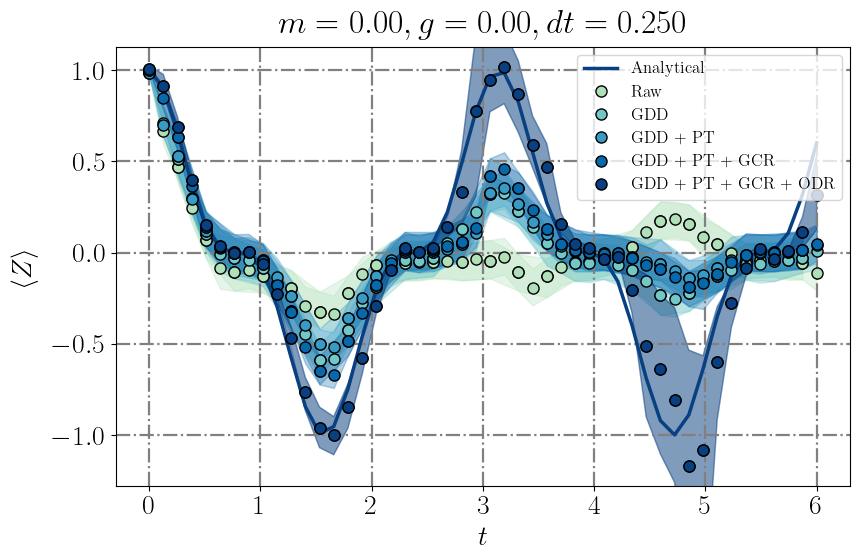

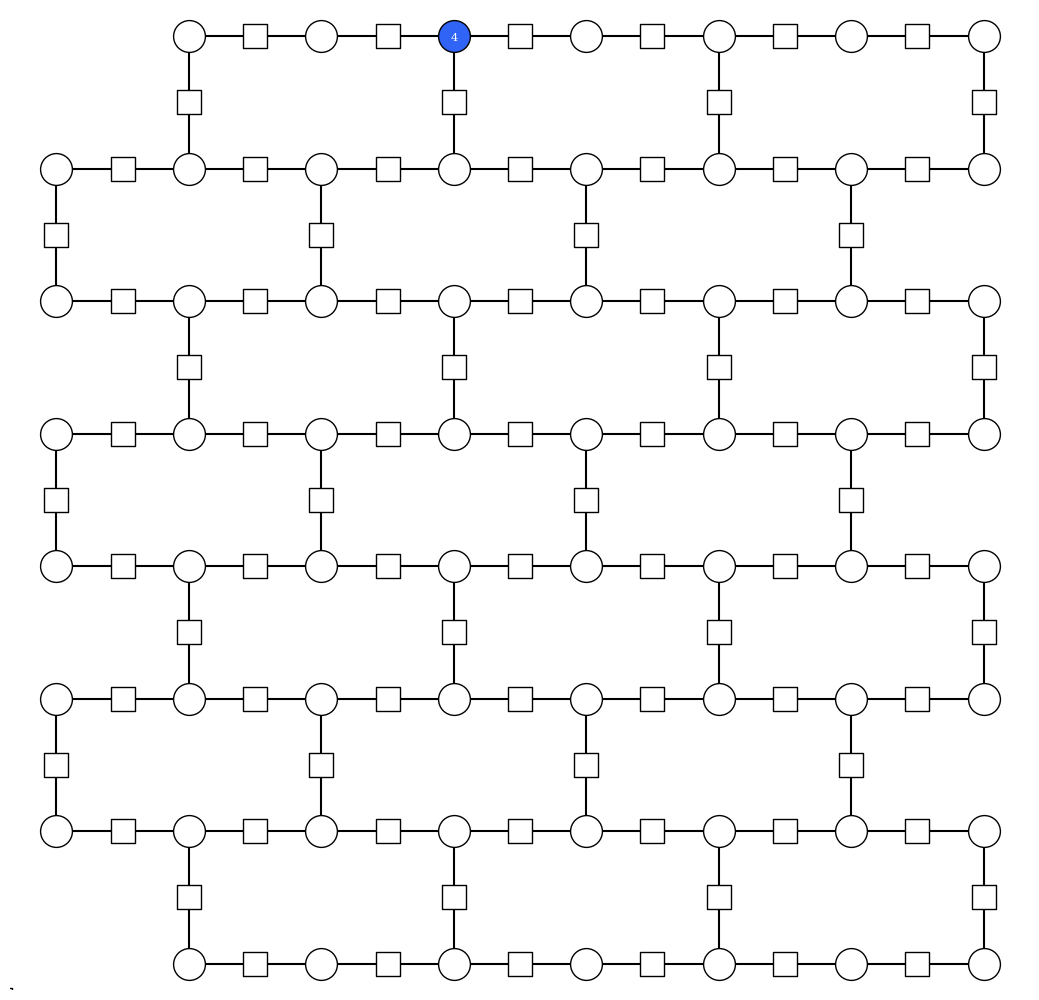

In [14]:
# from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

qubit = 4

plot_upto_time = 6
plot_upto = int(np.ceil(steps*plot_upto_time/final_time))
plot_step = 1

cmap = lambda x: plt.get_cmap("GnBu")((1.4*(x)+2.8)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, plot_upto_time, 7))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12
y_lim = "data"

funclabels = [
    "Raw",
    "GDD",
    "GDD + PT",
    "GDD + PT + GCR",
    "GDD + PT + GCR + ODR",
    "Analytical"
]

# plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
plot_filepath = "em_plot.pdf"
# legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"
legend_filepath = "em_plot_legend.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][3][:, qubit] for hdata in hardware_datas] + [hardware_datas[-1][0][1][:, qubit], hardware_datas[-1][0][0][:, qubit]])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 2, 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][3][:, qubit, :]
hardware_observables_confidences_to_plot[:, -2, :] = hardware_datas[-1][1][1][:, qubit, :]    
hardware_observables_confidences_to_plot[:, -1, :] = hardware_datas[-1][1][0][:, qubit, :]

hardware_observables_to_plot = hardware_observables_to_plot[:plot_upto:plot_step, :]
hardware_observables_confidences_to_plot = hardware_observables_confidences_to_plot[:plot_upto:plot_step, :, :]

# hardware_observables_to_plot[::2, :-1] = np.nan
# hardware_observables_confidences_to_plot[::2, :-1, :] = np.nan

tn_observable_to_plot = None #tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, lambda x: np.cos(2*x)**3, fmt="o--", x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, y_lim=y_lim, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

In [11]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
from z2hex.operators import local_pauli_z, postselection_operators
import matplotlib.pyplot as plt
from pymatching import Matching

def get_flip_distributions(samples_dict):
    observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
    postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)
    
    postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

    postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
    decoder = Matching(postselection_mask)

def plot_mean_flips(ax, samples_dicts, color, final_time):
    observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
    postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)
    
    postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

    postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
    decoder = Matching(postselection_mask)

    steps = len(samples_dicts)

    distribution_means = np.zeros(steps)
    standard_distributions = np.zeros(steps)
    for i in range(len(samples_dicts)):
        # all_layouts_samples_dicts = [samples_dicts[0][j][i] for j in range(len(samples_dicts[0]))]
        # combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
        combined_samples_dict = samples_dicts[i].copy()
        if combined_samples_dict == {}:
            distribution_means[i] = np.nan
            standard_distributions[i] = np.nan
        else:
            states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
            state_counts = np.array(list(combined_samples_dict.values()))
            states_syndromes = (states @ postselection_mask.T) % 2
            predicted_flips = decoder.decode_batch(states_syndromes)
            nflips = predicted_flips.sum(axis=1)
            unique_nflips = np.unique(nflips)
            this_flip_counts = {}
            this_total_nflips = 0
            for nf in unique_nflips:
                this_counts = np.sum(state_counts[np.equal(nflips, nf)])
                this_flip_counts[nf] = this_counts
                this_total_nflips += this_counts
            this_mean = 0
            for nf, counts in this_flip_counts.items():
                this_mean += nf*counts/this_total_nflips
            distribution_means[i] = this_mean
            for nf, counts in this_flip_counts.items():
                standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
            standard_distributions[i] = np.sqrt(standard_distributions[i])

    x = np.linspace(0, final_time, steps)
    x_ticks = np.round(np.linspace(0, final_time, 7)).astype(int)
    # ax.errorbar(x, distribution_means, yerr=standard_distributions, fmt="o--", color=plt.get_cmap("Set2")(1), markersize=10, elinewidth=2, markeredgecolor="black")
    plt.fill_between(x, distribution_means - standard_distributions, distribution_means + standard_distributions, color=color, alpha=0.3)
    ax.plot(x, distribution_means, "o--", markersize=10, markeredgecolor="black", color=color)

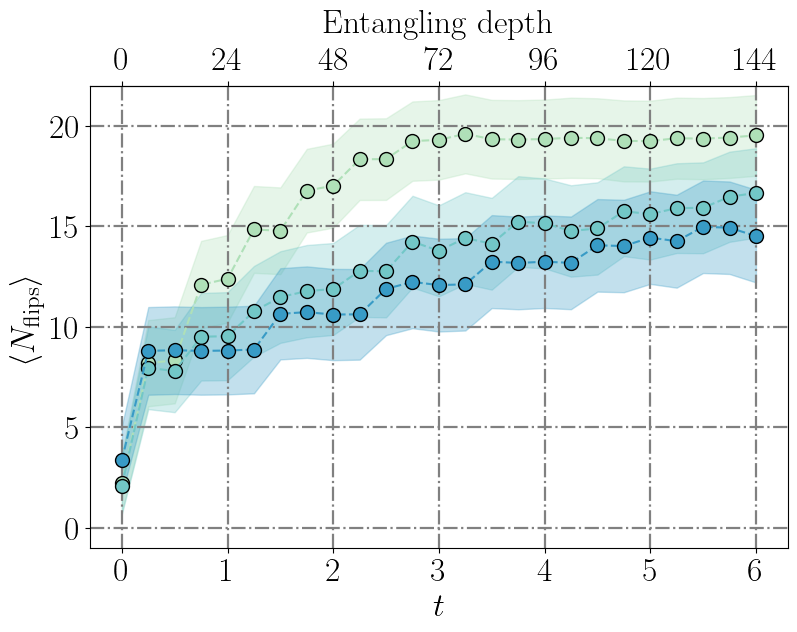

In [12]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
from z2hex.operators import local_pauli_z, postselection_operators
import matplotlib.pyplot as plt
from pymatching import Matching

plot_final_time = 6
cmap = lambda x: plt.get_cmap("GnBu")((1.4*(x)+2.8)/8)
x_ticks = np.round(np.linspace(0, plot_final_time, 7))

plt.rc("text", usetex=True)
plt.rc("font", size=24, family="serif", weight="bold")

fig, ax = plt.subplots(figsize=[9, 6])
all_samples_dicts = [hdata[2][0][0][:2*int(np.ceil(plot_final_time//dt))+1:2] if i != 2 else hdata[2][0][0][:int(np.ceil(plot_final_time//dt))+1] for i, hdata in enumerate(hardware_datas)]

observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_filepath = f"flip_distribution.pdf"

# plot_mean_flips(ax, all_samples_dicts[0], plt.get_cmap("Set2")(0), plot_final_time)

for i, samples in enumerate(all_samples_dicts):
    color = cmap(i)
    plot_mean_flips(ax, samples, color, plot_final_time)

ax.set_xticks(x_ticks)
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$\langle N_{\mathrm{flips}} \rangle$")
sax = ax.secondary_xaxis("top", functions=(lambda x: x/dt*6, lambda x: x*dt/6))
sax.set_xticks(np.round(x_ticks/dt*6))
sax.set_xlabel(r"Entangling depth", labelpad=10)
ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
ax.set_ylim([-1, 22])
plt.savefig(plot_filepath, dpi=300, facecolor="none")

In [ ]:
len(all_samples_dicts[0])

25

In [ ]:
2*int(np.ceil(plot_final_time//dt))+1

49

In [ ]:
plot_final_time = 6

In [ ]:
int(np.ceil(plot_final_time//dt))

24

In [ ]:
len(all_samples_dicts[0][0][0])

KeyError: 0